# Docking scores across exhaustiveness settings

Loads every `data/output/docking_scores-exhaustiv*<N>.csv` (one per Vina
`exhaustiveness` value used), combines them into a single dataframe, and
lists the strong binders (`best_affinity_kcal_mol <= -THRESHOLD`) for each
exhaustiveness separately.

In [1]:
import re
import sys
from pathlib import Path

import pandas as pd

REPO_ROOT = Path.cwd().resolve().parent
sys.path.insert(0, str(REPO_ROOT / "scripts"))
from paths import OUTPUT_DIR

# Binding-affinity cutoff (kcal/mol). A structure counts as a "hit" when
# best_affinity_kcal_mol <= -THRESHOLD (i.e. binds at least this strongly --
# affinities are negative, more negative = stronger).
THRESHOLD = 6

In [2]:
# Matches both the "exhaustiveness" and the misspelled "exhaustivness" file names.
FILENAME_RE = re.compile(r"^docking_scores-exhaustiveness(\d+)\.csv$")

score_files = sorted(OUTPUT_DIR.glob("docking_scores-*.csv"))
if not score_files:
    raise SystemExit(f"No docking_scores-*.csv files found in {OUTPUT_DIR}")

frames = []
for path in score_files:
    match = FILENAME_RE.match(path.name)
    if not match:
        print(f"Skipping {path.name}: doesn't match the expected naming pattern")
        continue
    df = pd.read_csv(path)
    df["exhaustiveness"] = int(match.group(1))
    frames.append(df)

scores = pd.concat(frames, ignore_index=True)
scores = scores.sort_values(["exhaustiveness", "best_affinity_kcal_mol"]).reset_index(drop=True)
scores

,receptor,best_affinity_kcal_mol,exhaustiveness
0,prot3_relaxed_0003,-7.360,4
1,prot3_relaxed_0005,-7.071,4
2,prot3_relaxed_0004,-7.037,4
3,prot3_relaxed_0001,-6.948,4
4,prot3_relaxed_0002,-6.741,4
...,...,...,...
217,prot2_relaxed_0001_flex,-5.063,512
218,prot4_relaxed_0002_flex,-5.024,512
219,prot4_relaxed_0002,-4.819,512
220,prot4_relaxed_0004_flex,-4.340,512


In [3]:
ex_hits = {}
for exhaustiveness, group in scores.groupby("exhaustiveness"):
    hits = group[group["best_affinity_kcal_mol"] <= -THRESHOLD].sort_values("best_affinity_kcal_mol")
    ex_hits[exhaustiveness] = hits
    print(f"exhaustiveness={exhaustiveness}: {len(hits)} structure(s) at or below -{THRESHOLD} kcal/mol")
    display(hits[["receptor", "best_affinity_kcal_mol"]])

exhaustiveness=4: 28 structure(s) at or below -6 kcal/mol


,receptor,best_affinity_kcal_mol
0,prot3_relaxed_0003,-7.360
1,prot3_relaxed_0005,-7.071
2,prot3_relaxed_0004,-7.037
3,prot3_relaxed_0001,-6.948
4,prot3_relaxed_0002,-6.741
5,6c2u_model_19,-6.718
6,prot2,-6.585
7,6c2u_model_9,-6.582
8,6c2u_model_7,-6.534
9,6c2u_model_13,-6.517


exhaustiveness=128: 31 structure(s) at or below -6 kcal/mol


,receptor,best_affinity_kcal_mol
60,prot3_relaxed_0003,-7.418
61,prot6_relaxed_0001,-7.273
62,prot3_relaxed_0005,-7.225
63,prot3_relaxed_0001,-7.152
64,prot3_relaxed_0002,-7.152
65,prot3_relaxed_0004,-7.143
66,prot3_relaxed_0005_flex,-6.941
67,prot2,-6.838
68,prot3_relaxed_0002_flex,-6.787
69,prot2_relaxed_0002_flex,-6.625


exhaustiveness=512: 34 structure(s) at or below -6 kcal/mol


,receptor,best_affinity_kcal_mol
141,prot3_relaxed_0003,-7.541
142,prot3_relaxed_0005,-7.204
143,prot3_relaxed_0004,-7.161
144,prot3_relaxed_0002,-7.157
145,prot3_relaxed_0001,-7.142
146,prot3_relaxed_0005_flex,-6.882
147,prot6_relaxed_0001,-6.874
148,prot7_relaxed_0002_flex,-6.869
149,prot3_relaxed_0002_flex,-6.828
150,prot3_relaxed_0003_flex,-6.698


In [4]:
for e, h in ex_hits.items():
    print(e, len(h))

4 28
128 31
512 34


In [5]:
prefix_sets = {}
prefix_hit_counts = {}

for ex, hits in ex_hits.items():
    prefixes = (
        hits["receptor"]
        .str.split("_", n=1)
        .str[0]
    )
    unique_prefixes = prefixes.drop_duplicates().tolist()
    counts = prefixes.value_counts().to_dict()

    prefix_sets[ex] = unique_prefixes
    prefix_hit_counts[ex] = {prefix: counts[prefix] for prefix in unique_prefixes}

    print(f"exhaustiveness={ex}:")
    for prefix in unique_prefixes:
        print(f"  {prefix}: {prefix_hit_counts[ex][prefix]}")

exhaustiveness=4:
  prot3: 5
  6c2u: 11
  prot2: 5
  prot1: 5
  prot7: 2
exhaustiveness=128:
  prot3: 10
  prot6: 1
  prot2: 7
  prot1: 6
  prot5: 1
  prot7: 5
  prot8: 1
exhaustiveness=512:
  prot3: 10
  prot6: 1
  prot7: 3
  prot2: 10
  prot8: 1
  prot1: 7
  prot5: 1
  prot4: 1


In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

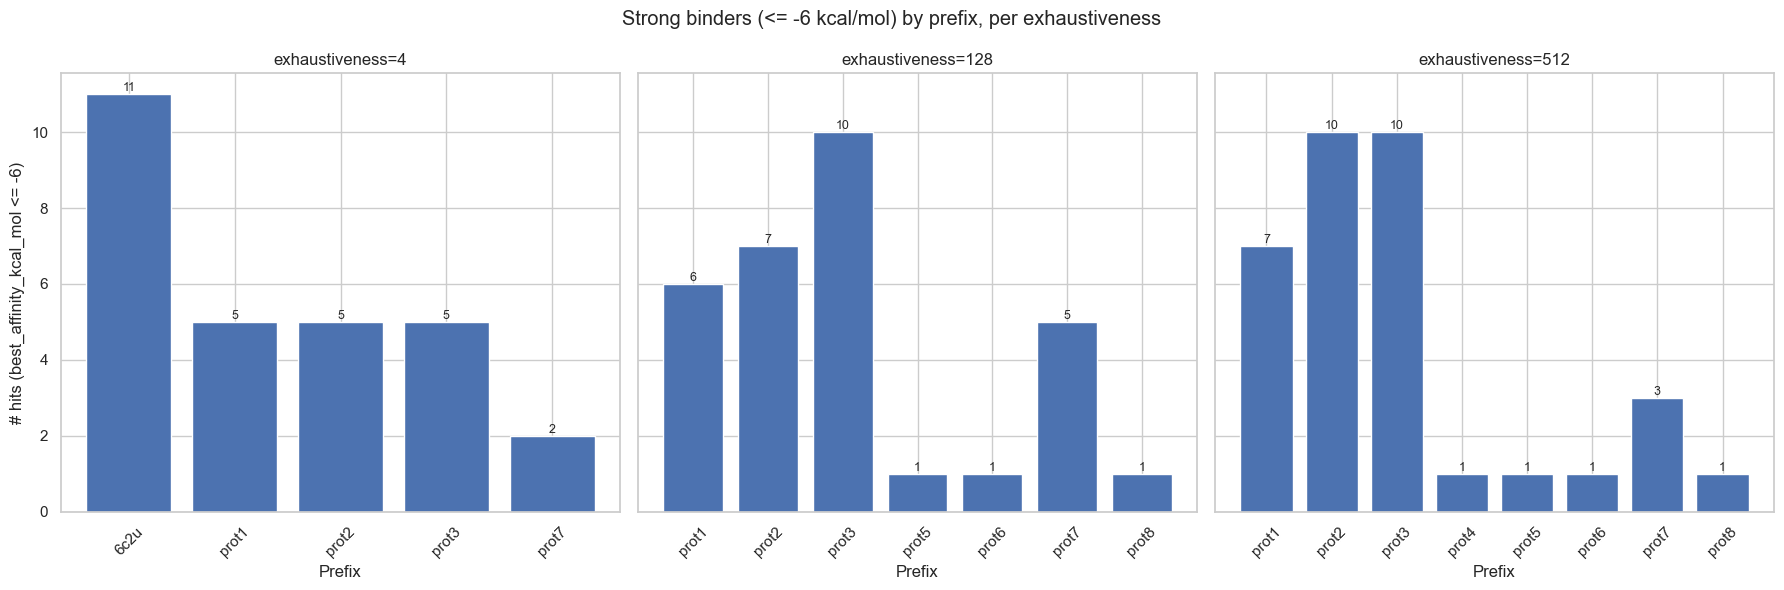

In [7]:
sns.set_theme(style="whitegrid")

exhaustivenesses = sorted(ex_hits.keys())

fig, axes = plt.subplots(1, len(exhaustivenesses), figsize=(6 * len(exhaustivenesses), 6), sharey=True)
if len(exhaustivenesses) == 1:
    axes = [axes]

for ax, ex in zip(axes, exhaustivenesses):
    prefixes = sorted(prefix_sets[ex])
    counts = [prefix_hit_counts[ex][prefix] for prefix in prefixes]
    bars = ax.bar(prefixes, counts, color=sns.color_palette("deep")[0])

    for bar in bars:
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height(),
            f"{int(bar.get_height())}",
            ha="center",
            va="bottom",
            fontsize=9,
        )

    ax.set_title(f"exhaustiveness={ex}")
    ax.set_xlabel("Prefix")
    ax.tick_params(axis="x", rotation=45)

axes[0].set_ylabel(f"# hits (best_affinity_kcal_mol <= -{THRESHOLD})")
fig.suptitle(f"Strong binders (<= -{THRESHOLD} kcal/mol) by prefix, per exhaustiveness")
fig.tight_layout()
plt.show()